# Stock Risk Report

**HW2 Part 2: parameterized single-stock report (Gobind Singh)**

This notebook reads one ticker's cleaned prices from `ohlc_hw_cleaned`, which Part 1 creates. It computes returns, rolling volatility, drawdown and the Sharpe ratio, then draws a 2x2 risk dashboard and a summary table. The next cell is tagged `parameters`, so papermill can rerun the notebook for any ticker and date range.

Run Part 1 first, then run this notebook from `Homeworks/HW2/GOBIND_SINGH/`.

In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # SQLite database containing ohlc_hw_cleaned

In [2]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/home/gobind/Desktop/Projects/MFE/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/GOBIND_SINGH/data/data.db"


In [3]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

TRADING_DAYS = 252
VOL_WINDOW = 20
MA_WINDOW = 50
RISK_FREE_RATE = 0.02
CLEAN_TABLE = "ohlc_hw_cleaned"

COLORS = {
    "price": "#1f4e79", "ma": "#ff8c00", "high": "#d62728", "low": "#2ca02c",
    "warmup": "#9e9e9e", "mean": "#333333", "drawdown": "#c0392b",
}

## Data loading

The inputs are validated first. A bad parameter or a ticker with no data in the window stops the notebook with a clear error, so the batch runner in Part 3 can record it as a failure. A window that is valid but short still produces a report, with `N/A` for any metric that needs more history: 20-day volatility needs 21 prices, and the 50-day average needs 50.

In [4]:
def validate_parameters(ticker, start_date, end_date, db_path):
    """Normalize and check the report parameters; raise ValueError or FileNotFoundError on bad input."""
    ticker = str(ticker).strip().upper()
    if not ticker:
        raise ValueError("ticker is empty")
    start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
    if end < start:
        raise ValueError(f"end_date {end_date} is before start_date {start_date}")
    if not Path(db_path).exists():
        raise FileNotFoundError(f"database not found: {Path(db_path).resolve()}")
    return ticker, start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d")


def load_prices(db_path, ticker, start_date, end_date):
    """Cleaned daily prices for one ticker between two ISO dates (inclusive), indexed and sorted by date."""
    query = (f"SELECT ts, open, high, low, close, adj_close, volume FROM {CLEAN_TABLE} "
             "WHERE ticker = ? AND ts BETWEEN ? AND ? ORDER BY ts")
    with closing(sqlite3.connect(db_path)) as conn:
        df = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date), parse_dates=["ts"])
    return df.set_index("ts")


ticker, start_date, end_date = validate_parameters(ticker, start_date, end_date, db_path)
df = load_prices(db_path, ticker, start_date, end_date)
if df.empty:
    raise ValueError(f"No cleaned data for {ticker} between {start_date} and {end_date}")

n_days = len(df)
first_date, last_date = df.index[0].strftime("%Y-%m-%d"), df.index[-1].strftime("%Y-%m-%d")
print(f"{ticker} from {start_date} to {end_date}: {n_days} trading days")
print(f"Actual coverage: {first_date} to {last_date}")
if first_date > start_date or last_date < end_date:
    print("Note: the data covers only part of the requested window; all metrics use the actual coverage.")
if n_days < VOL_WINDOW + 1:
    print(f"Insufficient history: {n_days} prices; {VOL_WINDOW}-day volatility needs {VOL_WINDOW + 1}.")
if n_days < MA_WINDOW:
    print(f"The {MA_WINDOW}-day moving average needs {MA_WINDOW} prices, so it is unavailable.")

IBM from 2024-06-01 to 2024-11-30: 126 trading days
Actual coverage: 2024-06-03 to 2024-11-29
Note: the data covers only part of the requested window; all metrics use the actual coverage.


In [5]:
pd.concat([df.head(3), df.tail(3)])

,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,166.54,166.78,163.53,165.28,162.57,2776100
2024-06-04,164.60,166.40,163.88,165.81,163.09,2594203
2024-06-05,166.41,167.79,165.78,167.38,164.63,3049400
2024-11-26,226.73,228.98,225.51,228.83,228.83,4449543
2024-11-27,228.83,229.19,224.27,226.92,226.92,2995121
2024-11-29,227.75,230.36,227.19,227.41,227.41,2640300


## Risk metrics

All metrics use **adjusted close**, so splits and dividends don't show up as price jumps. Volatility, the Sharpe ratio and the daily statistics use daily **log returns**. Values stay as fractions in calculations and are formatted as percentages only for display.

In [6]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns, ln(P_t / P_{t-1}). The first value is NaN."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility: rolling sample std of daily returns x sqrt(252).

    The value is NaN until a full window of returns exists (window + 1 prices). Warm-up gaps are left as NaN, not filled.
    """
    return returns.rolling(window, min_periods=window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak: (price - running max) / running max.

    It is 0 at a new high and negative below it, and it recovers when prices recover.
    The maximum drawdown for the period is this series' minimum.
    """
    running_max = prices.cummax()
    return (prices - running_max) / running_max


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio: (mean daily return x 252 - rf) / (daily std x sqrt(252)).

    Returns NaN with fewer than two returns or zero volatility, where the ratio is undefined.
    """
    r = returns.dropna()
    if len(r) < 2:
        return np.nan
    std = r.std(ddof=1)
    if not np.isfinite(std) or std == 0:
        return np.nan
    return (r.mean() * TRADING_DAYS - risk_free_rate) / (std * np.sqrt(TRADING_DAYS))


prices = df["adj_close"]
returns = calculate_returns(prices)
rolling_vol = calculate_volatility(returns, VOL_WINDOW)
drawdown = calculate_max_drawdown(prices)
moving_avg = prices.rolling(MA_WINDOW, min_periods=MA_WINDOW).mean()
sharpe = calculate_sharpe_ratio(returns, RISK_FREE_RATE)
mean_rolling_vol = rolling_vol.mean()

metrics = pd.DataFrame({"adj_close": prices, "log_return": returns, f"vol_{VOL_WINDOW}d": rolling_vol,
                        "drawdown": drawdown, f"ma_{MA_WINDOW}d": moving_avg})
print(f"Sharpe ratio: {sharpe:.2f}" if pd.notna(sharpe) else "Sharpe ratio: N/A")
print(f"Mean {VOL_WINDOW}-day rolling volatility: "
      + (f"{mean_rolling_vol:.2%}" if pd.notna(mean_rolling_vol) else "N/A"))
metrics.tail()

Sharpe ratio: 3.22
Mean 20-day rolling volatility: 19.93%


,adj_close,log_return,vol_20d,drawdown,ma_50d
ts,,,,,
2024-11-22,222.97,0.002560,0.241515,-0.044769,218.0336
2024-11-25,226.13,0.014073,0.241623,-0.031231,218.2470
2024-11-26,228.83,0.011869,0.236457,-0.019664,218.5744
2024-11-27,226.92,-0.008382,0.212190,-0.027847,218.8476
2024-11-29,227.41,0.002157,0.212125,-0.025748,219.1514


## Risk dashboard

In the price chart, the line is red when the 20-day volatility is above its average for this report and green when it is at or below it. It is gray during the first 20 days, before volatility can be estimated. This coloring is retrospective, because the average uses the whole window.

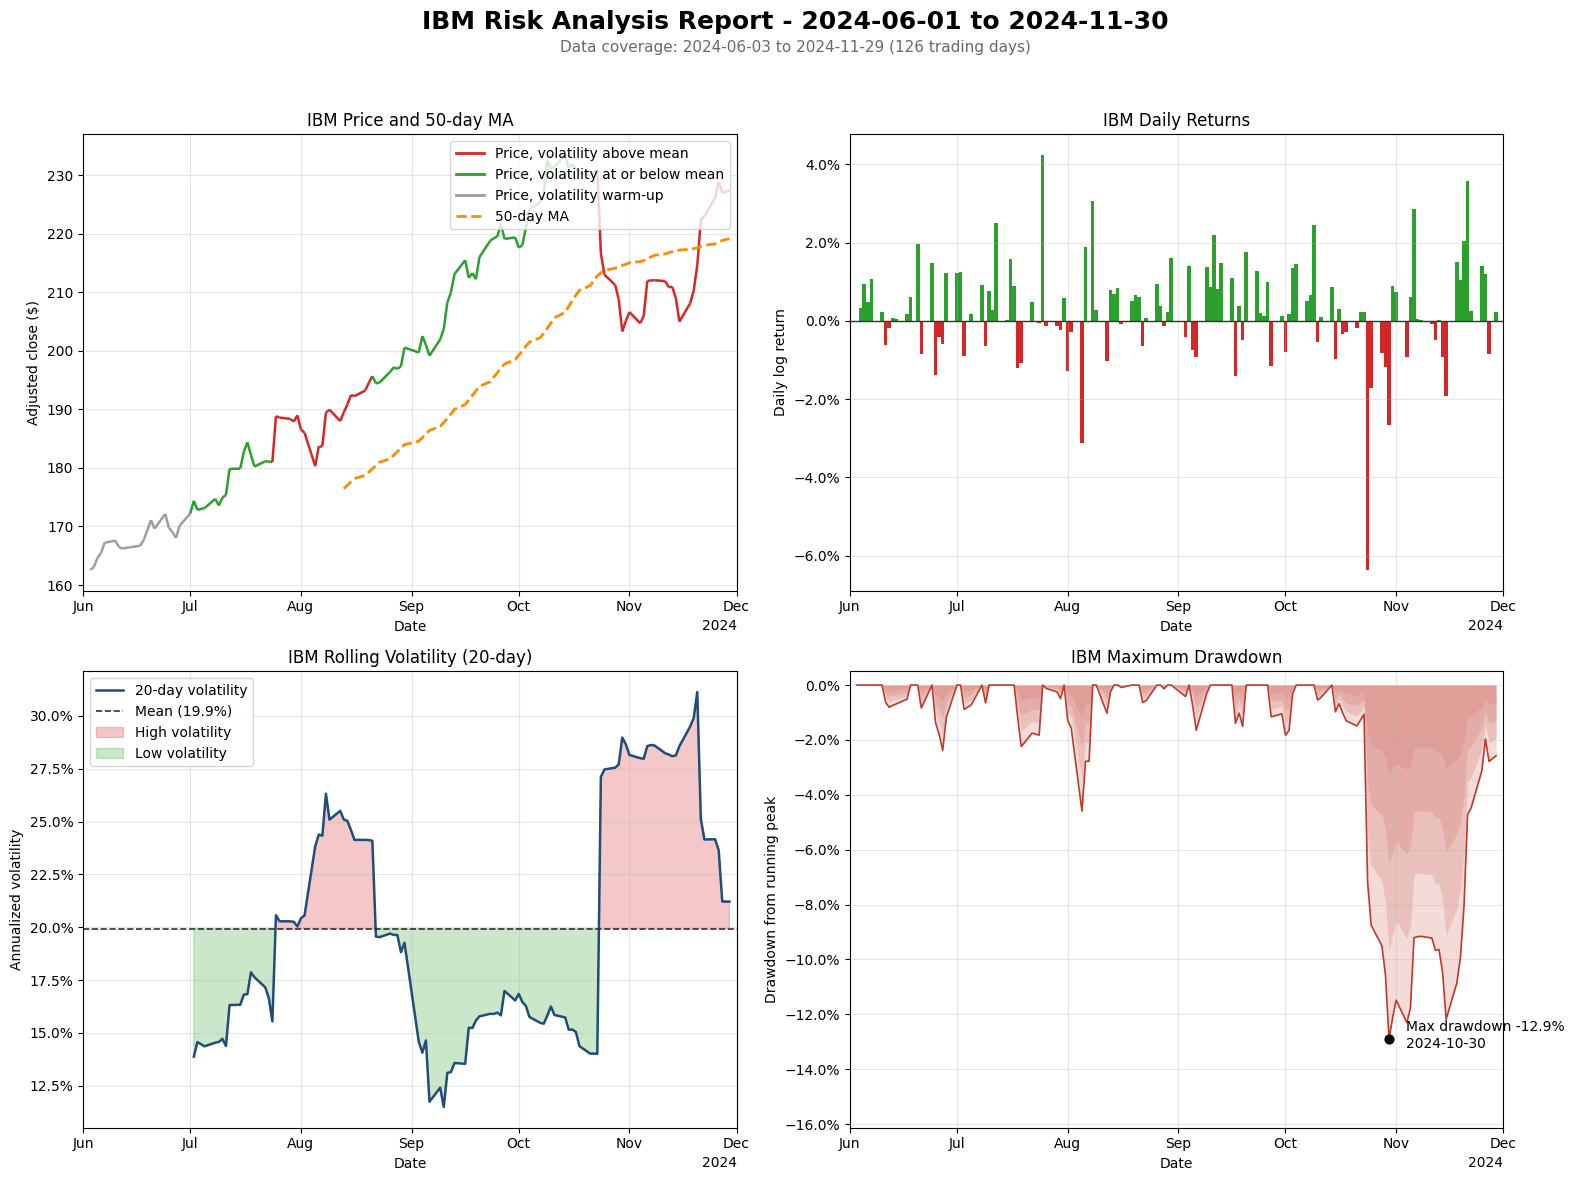

In [7]:
def colored_price_segments(dates, prices, vol, threshold):
    """Line segments between consecutive prices, colored by the volatility regime at each segment's end."""
    x = mdates.date2num(dates)
    points = np.column_stack([x, prices.to_numpy()])
    segments = np.stack([points[:-1], points[1:]], axis=1)
    v = vol.to_numpy()[1:]
    colors = np.where(np.isnan(v), COLORS["warmup"], np.where(v > threshold, COLORS["high"], COLORS["low"]))
    return LineCollection(segments, colors=colors, linewidths=1.8)


def show_unavailable(ax, message):
    """Write a centred note on an axis whose series could not be computed."""
    ax.text(0.5, 0.5, message, transform=ax.transAxes, ha="center", va="center",
            fontsize=11, color="dimgray", bbox={"facecolor": "white", "edgecolor": "lightgray"})


def plot_risk_report(ticker, start_date, end_date, prices, moving_avg, returns, rolling_vol, drawdown):
    """Draw the 2x2 risk dashboard: price with MA, daily returns, rolling volatility and drawdown."""
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    (ax_price, ax_ret), (ax_vol, ax_dd) = axes
    dates = prices.index
    mean_vol = rolling_vol.mean()

    if len(prices) > 1:
        ax_price.add_collection(colored_price_segments(dates, prices, rolling_vol, mean_vol))
    else:
        ax_price.plot(dates, prices, "o", color=COLORS["price"])
    ax_price.plot(dates, moving_avg, color=COLORS["ma"], lw=2, ls="--")
    ax_price.autoscale_view()
    if moving_avg.isna().all():
        show_unavailable(ax_price, f"{MA_WINDOW}-day MA unavailable: only {len(prices)} prices")
    ax_price.legend(handles=[
        Line2D([], [], color=COLORS["high"], lw=2, label="Price, volatility above mean"),
        Line2D([], [], color=COLORS["low"], lw=2, label="Price, volatility at or below mean"),
        Line2D([], [], color=COLORS["warmup"], lw=2, label="Price, volatility warm-up"),
        Line2D([], [], color=COLORS["ma"], lw=2, ls="--", label=f"{MA_WINDOW}-day MA"),
    ], loc="best")
    ax_price.set(title=f"{ticker} Price and 50-day MA", xlabel="Date", ylabel="Adjusted close ($)")

    defined = returns.dropna()
    bar_colors = np.where(defined >= 0, COLORS["low"], COLORS["high"])
    ax_ret.bar(defined.index, defined, color=bar_colors, width=1.0)
    if defined.empty:
        show_unavailable(ax_ret, "Needs at least 2 prices for a return")
    ax_ret.axhline(0, color=COLORS["mean"], lw=1)
    ax_ret.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax_ret.set(title=f"{ticker} Daily Returns", xlabel="Date", ylabel="Daily log return")

    if rolling_vol.notna().any():
        ax_vol.plot(dates, rolling_vol, color=COLORS["price"], lw=1.8, label=f"{VOL_WINDOW}-day volatility")
        ax_vol.axhline(mean_vol, color=COLORS["mean"], ls="--", lw=1.2, label=f"Mean ({mean_vol:.1%})")
        ax_vol.fill_between(dates, rolling_vol, mean_vol, where=rolling_vol > mean_vol, interpolate=True,
                            color=COLORS["high"], alpha=0.25, label="High volatility")
        ax_vol.fill_between(dates, rolling_vol, mean_vol, where=rolling_vol <= mean_vol, interpolate=True,
                            color=COLORS["low"], alpha=0.25, label="Low volatility")
        ax_vol.legend(loc="best")
    else:
        show_unavailable(ax_vol, f"Needs {VOL_WINDOW + 1} prices; have {len(prices)}")
    ax_vol.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax_vol.set(title=f"{ticker} Rolling Volatility (20-day)", xlabel="Date", ylabel="Annualized volatility")

    for depth, alpha in [(1.0, 0.18), (0.75, 0.16), (0.5, 0.14), (0.25, 0.12)]:
        ax_dd.fill_between(dates, drawdown * depth, 0, color=COLORS["drawdown"], alpha=alpha, lw=0)
    ax_dd.plot(dates, drawdown, color=COLORS["drawdown"], lw=1.2)
    worst = drawdown.idxmin()
    ax_dd.scatter([worst], [drawdown[worst]], color="black", zorder=5, s=40)
    ax_dd.annotate(f"Max drawdown {drawdown[worst]:.1%}\n{worst:%Y-%m-%d}", (worst, drawdown[worst]),
                   xytext=(12, -6), textcoords="offset points", fontsize=10)
    ax_dd.set_ylim(min(drawdown.min() * 1.25, -0.01), 0.005)
    ax_dd.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax_dd.set(title=f"{ticker} Maximum Drawdown", xlabel="Date", ylabel="Drawdown from running peak")

    pad = pd.Timedelta(days=2)
    for ax in axes.flat:
        ax.set_xlim(dates[0] - pad, dates[-1] + pad)
        ax.grid(alpha=0.3)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18, fontweight="bold")
    fig.text(0.5, 0.945, f"Data coverage: {dates[0]:%Y-%m-%d} to {dates[-1]:%Y-%m-%d} ({len(dates)} trading days)",
             ha="center", fontsize=11, color="dimgray")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig


fig = plot_risk_report(ticker, start_date, end_date, prices, moving_avg, returns, rolling_vol, drawdown)
plt.show()

## Summary statistics

| Metric | Definition |
|---|---|
| Total return | `last adj close / first adj close - 1` |
| Annualized return | `exp(sum(log returns) x 252 / n) - 1`, where `n` is the number of returns |
| Annualized volatility | Standard deviation of all daily log returns x sqrt(252), over the whole period (not the rolling average) |
| Sharpe ratio | As defined above, with a 2% risk-free rate |
| Maximum drawdown | Minimum of the drawdown series |
| Best day, worst day, average up day, average down day | From daily log returns |
| Positive days | Positive returns / all non-missing returns, including zero-return days |

In [8]:
def summary_statistics(prices, returns, drawdown, sharpe):
    """Whole-period summary metrics as fractions; NaN where a metric is undefined for this window."""
    r = returns.dropna()
    n = len(r)
    up, down = r[r > 0], r[r < 0]
    return {
        "Total Return": prices.iloc[-1] / prices.iloc[0] - 1 if len(prices) >= 2 else np.nan,
        "Annualized Return": np.exp(r.sum() * TRADING_DAYS / n) - 1 if n else np.nan,
        "Annualized Volatility": r.std(ddof=1) * np.sqrt(TRADING_DAYS) if n >= 2 else np.nan,
        "Sharpe Ratio": sharpe,
        "Maximum Drawdown": drawdown.min(),
        "Best Day": r.max() if n else np.nan,
        "Worst Day": r.min() if n else np.nan,
        "Positive Days": len(up) / n if n else np.nan,
        "Average Up Day": up.mean() if len(up) else np.nan,
        "Average Down Day": down.mean() if len(down) else np.nan,
    }


def format_metric(name, value):
    """Display format: signed percent for returns, plain percent for rates, two decimals for Sharpe."""
    if pd.isna(value):
        return "N/A"
    if name == "Sharpe Ratio":
        return f"{value:.2f}"
    if name in ("Annualized Volatility", "Positive Days"):
        return f"{value:.2%}"
    return f"{value:+.2%}"


stats = summary_statistics(prices, returns, drawdown, sharpe)
summary_table = pd.DataFrame({"Metric": list(stats), "Value": [format_metric(k, v) for k, v in stats.items()]})
print(f"{ticker}: {first_date} to {last_date} ({n_days} trading days)\n")
print(summary_table.to_string(index=False))

IBM: 2024-06-03 to 2024-11-29 (126 trading days)

               Metric   Value
         Total Return +39.88%
    Annualized Return +96.73%
Annualized Volatility  20.42%
         Sharpe Ratio    3.22
     Maximum Drawdown -12.90%
             Best Day  +4.24%
            Worst Day  -6.37%
        Positive Days  63.20%
       Average Up Day  +0.95%
     Average Down Day  -0.92%


## Reading this report

- **Price and 50-day MA.** A price above its 50-day average is in a recent uptrend. Red stretches mark periods when this stock was more volatile than usual for this window.
- **Daily returns.** Look for clusters of large bars. Volatility tends to bunch together.
- **Rolling volatility.** This is annualized: 30% means a typical one-year move of about plus or minus 30%. Shaded areas above the dashed mean are the high-risk periods.
- **Drawdown.** This is the loss from the last peak. The marked point is the worst loss an investor who bought at a peak would have seen in this window.
- **Sharpe ratio.** This is return per unit of risk after the 2% risk-free rate. Above 1 is strong, near 0 means the risk wasn't rewarded, and negative means the stock lost to cash. Over a short window it is noisy.

In [9]:
def as_float(value):
    """Plain Python float for scrapbook's JSON output; undefined metrics become None (JSON null)."""
    return float(value) if pd.notna(value) else None


report_summary = {
    "ticker": ticker, "start_date": start_date, "end_date": end_date,
    "first_date": first_date, "last_date": last_date, "trading_days": int(n_days),
    "total_return": as_float(stats["Total Return"]),
    "annualized_return": as_float(stats["Annualized Return"]),
    "annualized_volatility": as_float(stats["Annualized Volatility"]),
    "avg_volatility": as_float(mean_rolling_vol),
    "avg_daily_return": as_float(returns.mean()),
    "max_drawdown": as_float(stats["Maximum Drawdown"]),
    "sharpe_ratio": as_float(sharpe),
}
sb.glue("report_summary", report_summary, encoder="json")
print(f"Saved report_summary ({len(report_summary)} fields) for the Part 3 batch summary.")

Saved report_summary (13 fields) for the Part 3 batch summary.
